<a href="https://colab.research.google.com/github/alifihsan7/kelompok9-image-captioning/blob/main/notebooks/03_train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import drive
drive.mount('/content/drive')

ROOT = '/content/drive/MyDrive/Kelompok9'
import sys
sys.path.append(f'{ROOT}/src')

!nvidia-smi
!ls -R {ROOT} | head -50

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Sat Oct 31 09:13:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|          

In [6]:
%%writefile /content/drive/MyDrive/Kelompok9/src/train_utils.py
"""
src/train_utils.py
Modul pelatihan dan evaluasi PyTorch untuk Image Captioning (Kelompok 9).

Sesuai Kontrak Teknis Data V1:
- Input decoder: captions[:, :-1] (panjang T-1 = 29)
- Target label: captions[:, 1:] (panjang T-1 = 29)
- Loss: CrossEntropyLoss(ignore_index=0)
- Perataan dimensi: logits [B * 29, V] dan target [B * 29]
"""

import os
import csv
import time
import random
from pathlib import Path
from typing import Dict, List, Union

import numpy as np
import torch
import torch.nn as nn
from torch.optim import Optimizer
from torch.utils.data import DataLoader


def set_seed(seed: int = 42) -> None:
    """
    Mengunci seluruh generator bilangan acak untuk menjamin reproduksibilitas.

    Args:
        seed (int): Nilai seed acak (default: 42 sesuai kontrak).
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    optimizer: Optimizer,
    device: torch.device,
    clip: float = 5.0,
) -> float:
    """
    Melatih model selama satu epoch penuh menggunakan skema Teacher Forcing.

    Args:
        model (nn.Module): Model decoder image captioning.
        loader (DataLoader): DataLoader yang menghasilkan batch (features [B, 2048], captions [B, 30]).
        criterion (nn.Module): Fungsi kerugian (nn.CrossEntropyLoss dengan ignore_index=0).
        optimizer (Optimizer): Optimizer pembaruan bobot (Adam).
        device (torch.device): Perangkat komputasi (cuda atau cpu).
        clip (float, optional): Batas ambang maksimum pemotongan gradien (norm clipping). Default: 5.0.

    Returns:
        float: Rata-rata training loss pada epoch tersebut.
    """
    model.train()
    total_loss = 0.0
    num_batches = len(loader)

    for features, captions in loader:
        features = features.to(device, non_blocking=True)
        captions = captions.to(device, non_blocking=True)

        # Penjajaran Teacher Forcing:
        # Input decoder: membuang token terakhir [B, T-1] -> [B, 29]
        # Target label: membuang token awal <start> [B, T-1] -> [B, 29]
        captions_in = captions[:, :-1]
        targets = captions[:, 1:]

        optimizer.zero_grad()

        # Forward pass menghasilkan raw logits [B, 29, V]
        logits = model(features, captions_in)

        # Perataan dimensi sebelum masuk CrossEntropyLoss:
        # logits [B, 29, V] -> [B * 29, V]
        # targets [B, 29] -> [B * 29]
        vocab_size = logits.size(-1)
        loss = criterion(logits.reshape(-1, vocab_size), targets.reshape(-1))

        # Backward pass & Gradient clipping untuk menjaga kestabilan recurrent gate
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=clip)
        optimizer.step()

        total_loss += loss.item()

    return total_loss / num_batches if num_batches > 0 else 0.0


def evaluate(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
) -> float:
    """
    Mengevaluasi loss model pada dataset validasi tanpa komputasi gradien.

    Args:
        model (nn.Module): Model decoder image captioning.
        loader (DataLoader): DataLoader validasi (features [B, 2048], captions [B, 30]).
        criterion (nn.Module): Fungsi kerugian (nn.CrossEntropyLoss dengan ignore_index=0).
        device (torch.device): Perangkat komputasi.

    Returns:
        float: Rata-rata validation loss.
    """
    model.eval()
    total_loss = 0.0
    num_batches = len(loader)

    with torch.no_grad():
        for features, captions in loader:
            features = features.to(device, non_blocking=True)
            captions = captions.to(device, non_blocking=True)

            captions_in = captions[:, :-1]
            targets = captions[:, 1:]

            logits = model(features, captions_in)
            vocab_size = logits.size(-1)
            loss = criterion(logits.reshape(-1, vocab_size), targets.reshape(-1))

            total_loss += loss.item()

    return total_loss / num_batches if num_batches > 0 else 0.0


def fit(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    epochs: int,
    lr: float,
    device: torch.device,
    exp_name: str,
    root: Union[str, Path] = ".",
) -> Dict[str, List[float]]:
    """
    Loop pelatihan multi-epoch dengan optimizer Adam, penyimpanan checkpoint terbaik,
    serta pencatatan riwayat metrik per epoch ke berkas CSV.

    Args:
        model (nn.Module): Model decoder image captioning.
        train_loader (DataLoader): DataLoader subset training.
        val_loader (DataLoader): DataLoader subset validasi.
        epochs (int): Jumlah iterasi pelatihan.
        lr (float): Learning rate untuk optimizer Adam.
        device (torch.device): Perangkat komputasi (cuda / cpu).
        exp_name (str): Nama eksperimen (misalnya: 'baseline_E0').
        root (Union[str, Path], optional): Jalur folder root proyek Google Drive. Default: '.'.

    Returns:
        Dict[str, List[float]]: Kamus rekapitulasi riwayat metrik selama pelatihan.
    """
    root_path = Path(root)
    checkpoints_dir = root_path / "checkpoints"
    results_dir = root_path / "results"

    checkpoints_dir.mkdir(parents=True, exist_ok=True)
    results_dir.mkdir(parents=True, exist_ok=True)

    checkpoint_file = checkpoints_dir / f"best_{exp_name}.pt"
    csv_file = results_dir / f"{exp_name}.csv"

    # Hanya daftarkan parameter yang memerlukan gradien ke Adam
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable_params, lr=lr)

    # Fungsi kerugian standar dengan masking padding token <pad>=0
    criterion = nn.CrossEntropyLoss(ignore_index=0)

    best_val_loss = float("inf")
    history: Dict[str, List[float]] = {
        "epoch": [],
        "train_loss": [],
        "val_loss": [],
        "lr": [],
        "seconds": [],
    }

    # Buat berkas CSV baru beserta header kolomnya
    with open(csv_file, mode="w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["epoch", "train_loss", "val_loss", "lr", "seconds"])

    print(f"Mulai eksperimen: {exp_name} | Epochs: {epochs} | LR: {lr} | Target Device: {device}")
    print("-" * 80)

    for epoch in range(1, epochs + 1):
        start_time = time.time()

        train_loss = train_one_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=device,
            clip=5.0,
        )

        val_loss = evaluate(
            model=model,
            loader=val_loader,
            criterion=criterion,
            device=device,
        )

        elapsed_seconds = round(time.time() - start_time, 2)
        current_lr = optimizer.param_groups[0]["lr"]

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["lr"].append(current_lr)
        history["seconds"].append(elapsed_seconds)

        # Tulis entri epoch ke berkas CSV
        with open(csv_file, mode="a", newline="", encoding="utf-8") as f:
            writer = csv.writer(f)
            writer.writerow([epoch, f"{train_loss:.4f}", f"{val_loss:.4f}", f"{current_lr:.6f}", elapsed_seconds])

        # Periksa dan simpan model checkpoint terbaik berbasis val_loss terendah
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            checkpoint_payload = {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": val_loss,
                "train_loss": train_loss,
                "lr": current_lr,
                "exp_name": exp_name,
            }
            torch.save(checkpoint_payload, checkpoint_file)
            status_simpan = " [BEST SAVED]"
        else:
            status_simpan = ""

        print(
            f"Epoch [{epoch:02d}/{epochs:02d}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"LR: {current_lr:.6f} | "
            f"Waktu: {elapsed_seconds:>5.2f}s{status_simpan}"
        )

    print("-" * 80)
    print(f"Selesai! Checkpoint terbaik tersimpan di : {checkpoint_file}")
    print(f"Log pelatihan tersimpan di               : {csv_file}")

    return history

Writing /content/drive/MyDrive/Kelompok9/src/train_utils.py


In [10]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from pathlib import Path

# Impor modul yang baru saja disimpan
from train_utils import set_seed, train_one_epoch, evaluate, fit

# 1. Kunci seed sesuai kontrak
set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Perangkat yang aktif: {device}")

# 2. Definisikan Dummy Model yang menerima (features [B, 2048], captions_in [B, 29]) -> logits [B, 29, V]
class DummyDecoder(nn.Module):
    def __init__(self, vocab_size=3000, feature_dim=2048, hidden_size=512):
        super().__init__()
        self.fc_feat = nn.Linear(feature_dim, hidden_size)
        self.fc_text = nn.Linear(hidden_size, vocab_size)
        self.embedding = nn.Embedding(vocab_size, hidden_size, padding_idx=0)

    def forward(self, features, captions_in):
        # [B, 29] -> [B, 29, 512]
        emb = self.embedding(captions_in)
        # [B, 2048] -> [B, 1, 512]
        feat = self.fc_feat(features).unsqueeze(1)
        # Sinergi dummy fitur visual dan kata
        combined = emb + feat
        logits = self.fc_text(combined)  # [B, 29, vocab_size]
        return logits

# 3. Parameter dummy data
N_train, N_val = 64, 32
B = 16
V = 3000
T = 30  # Panjang sekuens caption asli

# 4. Bangun tensor dummy sesuai kontrak
dummy_train_features = torch.randn(N_train, 2048, dtype=torch.float32)
dummy_train_captions = torch.randint(0, V, (N_train, T), dtype=torch.long)
# Sisipkan token padding (<pad>=0) pada akhir sekuens untuk verifikasi ignore_index
dummy_train_captions[:, 25:] = 0

dummy_val_features = torch.randn(N_val, 2048, dtype=torch.float32)
dummy_val_captions = torch.randint(0, V, (N_val, T), dtype=torch.long)
dummy_val_captions[:, 25:] = 0

train_loader = DataLoader(TensorDataset(dummy_train_features, dummy_train_captions), batch_size=B, shuffle=True)
val_loader = DataLoader(TensorDataset(dummy_val_features, dummy_val_captions), batch_size=B, shuffle=False)

# 5. Uji fungsional loop pelatihan menggunakan fit()
dummy_model = DummyDecoder(vocab_size=V).to(device)
temp_root = Path("./temp_Kelompok9")

history = fit(
    model=dummy_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=2,
    lr=1e-3,
    device=device,
    exp_name="dummy_test",
    root=temp_root
)

# 6. Verifikasi keberadaan output file
checkpoint_path = temp_root / "checkpoints" / "best_dummy_test.pt"
csv_path = temp_root / "results" / "dummy_test.csv"

assert checkpoint_path.is_file(), "File checkpoint gagal dibuat!"
assert csv_path.is_file(), "File CSV riwayat metrik gagal dibuat!"

print("\n✅ Verifikasi modul train_utils.py SUKSES:")
print(f"- Checkpoint tervalidasi di : {checkpoint_path}")
print(f"- CSV tervalidasi di        : {csv_path}")

Perangkat yang aktif: cuda
Mulai eksperimen: dummy_test | Epochs: 2 | LR: 0.001 | Target Device: cuda
--------------------------------------------------------------------------------
Epoch [01/02] | Train Loss: 8.2084 | Val Loss: 8.2336 | LR: 0.001000 | Waktu:  0.64s [BEST SAVED]
Epoch [02/02] | Train Loss: 5.8339 | Val Loss: 8.2320 | LR: 0.001000 | Waktu:  0.02s [BEST SAVED]
--------------------------------------------------------------------------------
Selesai! Checkpoint terbaik tersimpan di : temp_Kelompok9/checkpoints/best_dummy_test.pt
Log pelatihan tersimpan di               : temp_Kelompok9/results/dummy_test.csv

✅ Verifikasi modul train_utils.py SUKSES:
- Checkpoint tervalidasi di : temp_Kelompok9/checkpoints/best_dummy_test.pt
- CSV tervalidasi di        : temp_Kelompok9/results/dummy_test.csv


In [11]:
%%writefile /content/drive/MyDrive/Kelompok9/src/eval_utils.py
"""
src/eval_utils.py
Modul evaluasi metrik dan visualisasi inferensi Image Captioning (Kelompok 9).

Sesuai Kontrak Teknis Data V1:
- Token khusus: <pad>=0, <start>=1, <end>=2, <unk>=3
- Evaluasi corpus_bleu NLTK dengan SmoothingFunction().method1
- Visualisasi kurva loss train vs val dari log CSV fit()
"""

import csv
from pathlib import Path
from typing import Dict, List, Tuple, Union

import matplotlib
import matplotlib.pyplot as plt
import nltk
from nltk.translate.bleu_score import SmoothingFunction, corpus_bleu
import torch
import torch.nn as nn


def decode_tokens(
    ids: Union[torch.Tensor, List[int]],
    idx2word: Dict[int, str],
) -> List[str]:
    """
    Mengonversi sekuens ID token menjadi deretan kata teks (list of words).

    Aturan Kontrak Teknis Data V1:
    - Menghentikan proses saat token <end> (ID 2) ditemukan.
    - Mengabaikan token <start> (ID 1) dan <pad> (ID 0).
    - Memetakan token lainnya ke kata aslinya via kamus idx2word (fallback ke '<unk>').

    Args:
        ids (Union[torch.Tensor, List[int]]): Sekuens ID token (1D tensor atau list int).
        idx2word (Dict[int, str]): Kamus pemetaan ID integer ke kata teks.

    Returns:
        List[str]: Daftar kata hasil rekonstruksi bersih dari token pembatas.
    """
    if isinstance(ids, torch.Tensor):
        ids = ids.detach().cpu().tolist()

    # Ratakan jika input berupa list bersarang 2D [1, L]
    if len(ids) > 0 and isinstance(ids[0], list):
        ids = ids[0]

    words: List[str] = []
    for token_id in ids:
        token_id = int(token_id)
        if token_id == 2:  # Token <end>
            break
        if token_id in (0, 1):  # Abaikan <pad> dan <start>
            continue
        words.append(idx2word.get(token_id, "<unk>"))

    return words


def evaluate_bleu(
    model: nn.Module,
    eval_items: List[Tuple[torch.Tensor, List[List[str]]]],
    idx2word: Dict[int, str],
    device: torch.device,
    batch_size: int = 64,
    max_len: int = 30,
) -> Dict[str, float]:
    """
    Menghitung metrik korpus BLEU-1 sampai BLEU-4 terhadap kumpulan data evaluasi.

    Args:
        model (nn.Module): Model decoder image captioning dengan method generate_greedy.
        eval_items (List[Tuple[torch.Tensor, List[List[str]]]]): Pasangan (fitur [2048], 5 caption referensi).
        idx2word (Dict[int, str]): Kamus ID kata ke teks string.
        device (torch.device): Perangkat komputasi GPU/CPU.
        batch_size (int, optional): Ukuran mini-batch evaluasi. Default: 64.
        max_len (int, optional): Batas panjang inferensi greedy. Default: 30.

    Returns:
        Dict[str, float]: Skor metrik BLEU-1, BLEU-2, BLEU-3, dan BLEU-4.
    """
    model.eval()
    references: List[List[List[str]]] = []
    hypotheses: List[List[str]] = []

    with torch.no_grad():
        for i in range(0, len(eval_items), batch_size):
            batch = eval_items[i : i + batch_size]
            batch_feats = torch.stack([item[0] for item in batch]).to(device)

            for item in batch:
                references.append(item[1])

            # Fleksibilitas inferensi: batch Tensor [B, L] atau iterasi per citra [1, 2048]
            try:
                preds = model.generate_greedy(batch_feats, max_len=max_len)
                if isinstance(preds, torch.Tensor):
                    preds = preds.detach().cpu().tolist()
                for pred_ids in preds:
                    hypotheses.append(decode_tokens(pred_ids, idx2word))
            except (TypeError, ValueError):
                # Fallback otomatis jika CaptionDecoder hanya menerima 1 citra per iterasi
                for item in batch:
                    single_feat = item[0].to(device)
                    pred = model.generate_greedy(single_feat, max_len=max_len)
                    if isinstance(pred, torch.Tensor):
                        pred = pred.detach().cpu().tolist()
                    hypotheses.append(decode_tokens(pred, idx2word))

    smooth = SmoothingFunction().method1
    bleu1 = corpus_bleu(references, hypotheses, weights=(1.0, 0.0, 0.0, 0.0), smoothing_function=smooth)
    bleu2 = corpus_bleu(references, hypotheses, weights=(0.5, 0.5, 0.0, 0.0), smoothing_function=smooth)
    bleu3 = corpus_bleu(references, hypotheses, weights=(1.0 / 3.0, 1.0 / 3.0, 1.0 / 3.0, 0.0), smoothing_function=smooth)
    bleu4 = corpus_bleu(references, hypotheses, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smooth)

    return {
        "BLEU-1": float(bleu1),
        "BLEU-2": float(bleu2),
        "BLEU-3": float(bleu3),
        "BLEU-4": float(bleu4),
    }


def plot_history(
    csv_path: Union[str, Path],
    save_path: Union[str, Path],
) -> None:
    """
    Membuat grafik garis train_loss vs val_loss per epoch dari berkas CSV log hasil fit()
    dan menyimpannya sebagai file citra PNG.

    Args:
        csv_path (Union[str, Path]): Jalur berkas CSV riwayat pelatihan.
        save_path (Union[str, Path]): Jalur tujuan penyimpanan grafik format PNG.
    """
    csv_path = Path(csv_path)
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)

    epochs: List[int] = []
    train_losses: List[float] = []
    val_losses: List[float] = []

    with open(csv_path, mode="r", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row in reader:
            epochs.append(int(row["epoch"]))
            train_losses.append(float(row["train_loss"]))
            val_losses.append(float(row["val_loss"]))

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, train_losses, marker="o", color="#1f77b4", linewidth=2, label="Train Loss")
    plt.plot(epochs, val_losses, marker="s", color="#d62728", linewidth=2, label="Val Loss")

    plt.title(f"Kurva Loss Pelatihan ({csv_path.stem})", fontsize=13, fontweight="bold")
    plt.xlabel("Epoch", fontsize=11)
    plt.ylabel("Loss (CrossEntropy)", fontsize=11)
    if len(epochs) > 0:
        plt.xticks(epochs)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend(fontsize=11)
    plt.tight_layout()

    plt.savefig(save_path, dpi=300)
    plt.close()


def show_samples(
    model: nn.Module,
    eval_items: List[Tuple[torch.Tensor, List[List[str]]]],
    idx2word: Dict[int, str],
    device: torch.device,
    n: int = 10,
) -> None:
    """
    Mencetak sampel hasil prediksi caption model berdampingan dengan 1 caption referensi.

    Args:
        model (nn.Module): Model captioning dengan method generate_greedy.
        eval_items (List[Tuple[torch.Tensor, List[List[str]]]]): Pasangan (fitur [2048], 5 caption referensi).
        idx2word (Dict[int, str]): Kamus pemetaan ID token ke kata.
        device (torch.device): Perangkat komputasi aktif.
        n (int, optional): Jumlah sampel representatif yang dicetak. Default: 10.
    """
    model.eval()
    num_samples = min(n, len(eval_items))

    print(f"\n{'='*78}")
    print(f"HASIL PREDIKSI MODEL VS REFERENSI ({num_samples} SAMPEL)")
    print(f"{'='*78}")

    with torch.no_grad():
        for i in range(num_samples):
            feature, references = eval_items[i]
            feat_input = feature.unsqueeze(0).to(device) if feature.dim() == 1 else feature.to(device)

            try:
                pred = model.generate_greedy(feat_input, max_len=30)
            except (TypeError, ValueError):
                pred = model.generate_greedy(feature.to(device), max_len=30)

            if isinstance(pred, torch.Tensor):
                pred = pred.detach().cpu().tolist()
                if len(pred) > 0 and isinstance(pred[0], list):
                    pred = pred[0]

            pred_words = decode_tokens(pred, idx2word)
            pred_text = " ".join(pred_words) if pred_words else "<empty>"

            ref_words = references[0] if len(references) > 0 else []
            ref_text = " ".join(ref_words) if ref_words else "<empty>"

            print(f"[{i+1:02d}]")
            print(f"  Prediksi : {pred_text}")
            print(f"  Referensi: {ref_text}")
            print("-" * 78)

Writing /content/drive/MyDrive/Kelompok9/src/eval_utils.py


In [13]:
import sys
import csv
from pathlib import Path
import torch
import torch.nn as nn

# Pastikan subfolder src dikenali oleh sys.path
src_path = "/content/drive/MyDrive/Kelompok9/src"
if src_path not in sys.path:
    sys.path.insert(0, src_path)

from eval_utils import decode_tokens, evaluate_bleu, plot_history, show_samples

print("Memulai pengujian unit modul eval_utils.py...")

# 1. Uji decode_tokens
idx2word_dummy = {
    0: "<pad>",
    1: "<start>",
    2: "<end>",
    3: "<unk>",
    4: "dog",
    5: "runs",
    6: "on",
    7: "the",
    8: "green",
    9: "grass",
}
# Contoh tensor: <start> dog runs on <end> <pad> <pad>
raw_ids = torch.tensor([1, 4, 5, 6, 2, 0, 0], dtype=torch.long)
decoded_words = decode_tokens(raw_ids, idx2word_dummy)
print(f"Uji decode_tokens: {decoded_words}")
assert decoded_words == ["dog", "runs", "on"], f"Decode gagal: {decoded_words}"
print("✅ Uji 1: decode_tokens berhasil menyaring <start>, <pad>, dan berhenti di <end>.")

# 2. Definisikan Model Dummy yang memiliki method generate_greedy
class DummyGreedyModel(nn.Module):
    def __init__(self, vocab_size=10):
        super().__init__()
        self.vocab_size = vocab_size

    def generate_greedy(self, features: torch.Tensor, max_len: int = 30) -> torch.Tensor:
        # Menghasilkan batch token acak [B, 6] berakhiran token <end> (2)
        batch_size = features.shape[0] if features.dim() == 2 else 1
        tokens = torch.randint(4, self.vocab_size, (batch_size, 5), dtype=torch.long)
        end_token = torch.full((batch_size, 1), 2, dtype=torch.long)
        res = torch.cat([tokens, end_token], dim=1)
        return res if features.dim() == 2 else res.squeeze(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dummy_model = DummyGreedyModel(vocab_size=10).to(device)

# 3. Bentuk eval_items dummy (16 sampel, masing-masing dengan 5 caption referensi)
dummy_eval_items = []
sample_references = [
    ["dog", "runs", "on", "the", "green", "grass"],
    ["a", "brown", "dog", "playing", "outdoors"],
    ["dog", "running", "in", "park"],
    ["canine", "sprinting", "across", "lawn"],
    ["pets", "exercising", "in", "field"],
]

for _ in range(16):
    dummy_feat = torch.randn(2048, dtype=torch.float32)
    dummy_eval_items.append((dummy_feat, sample_references))

# 4. Uji evaluate_bleu
bleu_scores = evaluate_bleu(
    model=dummy_model,
    eval_items=dummy_eval_items,
    idx2word=idx2word_dummy,
    device=device,
    batch_size=8,
    max_len=15,
)
print("\nSkor BLEU Dummy:")
for metric, score in bleu_scores.items():
    print(f"  {metric}: {score:.4f}")
    assert 0.0 <= score <= 1.0, f"Skor {metric} berada di luar batas valid [0, 1]!"
print("✅ Uji 2: evaluate_bleu (BLEU-1 s.d. BLEU-4) tereksekusi mulus.")

# 5. Uji plot_history menggunakan CSV hasil fit() sebelumnya
csv_test_path = Path("temp_Kelompok9/results/dummy_test.csv")
png_save_path = Path("temp_Kelompok9/results/dummy_loss_curve.png")

# Antisipasi jika berkas belum ada saat dijalankan terpisah
if not csv_test_path.is_file():
    csv_test_path.parent.mkdir(parents=True, exist_ok=True)
    with open(csv_test_path, mode="w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["epoch", "train_loss", "val_loss", "lr", "seconds"])
        writer.writerow([1, "8.2084", "8.2336", "0.001000", 1.25])
        writer.writerow([2, "5.8339", "8.2320", "0.001000", 1.18])

plot_history(csv_path=csv_test_path, save_path=png_save_path)
assert png_save_path.is_file(), "File grafik PNG gagal dibuat!"
print(f"✅ Uji 3: plot_history berhasil membuat grafik di {png_save_path}")

# 6. Uji show_samples
show_samples(
    model=dummy_model,
    eval_items=dummy_eval_items,
    idx2word=idx2word_dummy,
    device=device,
    n=3,
)
print("✅ Uji 4: show_samples berhasil menampilkan komparasi sampel.")
print("\nSeluruh pengujian unit src/eval_utils.py SUKSES!")

Memulai pengujian unit modul eval_utils.py...
Uji decode_tokens: ['dog', 'runs', 'on']
✅ Uji 1: decode_tokens berhasil menyaring <start>, <pad>, dan berhenti di <end>.

Skor BLEU Dummy:
  BLEU-1: 0.7250
  BLEU-2: 0.2607
  BLEU-3: 0.0521
  BLEU-4: 0.0258
✅ Uji 2: evaluate_bleu (BLEU-1 s.d. BLEU-4) tereksekusi mulus.
✅ Uji 3: plot_history berhasil membuat grafik di temp_Kelompok9/results/dummy_loss_curve.png

HASIL PREDIKSI MODEL VS REFERENSI (3 SAMPEL)
[01]
  Prediksi : runs dog grass dog grass
  Referensi: dog runs on the green grass
------------------------------------------------------------------------------
[02]
  Prediksi : on grass on grass the
  Referensi: dog runs on the green grass
------------------------------------------------------------------------------
[03]
  Prediksi : runs dog on dog the
  Referensi: dog runs on the green grass
------------------------------------------------------------------------------
✅ Uji 4: show_samples berhasil menampilkan komparasi sampel.

S

In [14]:
!ls -la /content/drive/MyDrive/Kelompok9/src /content/drive/MyDrive/Kelompok9/features /content/drive/MyDrive/Kelompok9/data

/content/drive/MyDrive/Kelompok9/data:
total 2173092
drwx------ 2 root root       4096 Oct 30 16:02 .
drwx------ 8 root root       4096 Oct 30 16:01 ..
-rw------- 1 root root 1112618566 Oct 31 08:18 flickr8.zip
-rw------- 1 root root 1112618566 Oct 31 08:22 flickr.zip

/content/drive/MyDrive/Kelompok9/features:
total 68605
drwx------ 2 root root     4096 Oct 30 16:02 .
drwx------ 8 root root     4096 Oct 30 16:01 ..
-rw------- 1 root root  2770533 Oct 31 08:24 captions.json
-rw------- 1 root root 67154566 Oct 31 08:28 features.pt
-rw------- 1 root root   265296 Oct 31 08:24 splits.json
-rw------- 1 root root    50759 Oct 31 08:24 vocab.pkl

/content/drive/MyDrive/Kelompok9/src:
total 41
drwx------ 3 root root 4096 Oct 31 09:22 .
drwx------ 8 root root 4096 Oct 30 16:01 ..
-rw------- 1 root root 3247 Oct 31 08:13 dataset.py
-rw------- 1 root root 8024 Oct 31 09:22 eval_utils.py
-rw------- 1 root root 8709 Oct 31 09:11 model.py
drwx------ 2 root root 4096 Oct 31 09:23 __pycache__
-rw----

In [15]:
!cat /content/drive/MyDrive/Kelompok9/src/model.py
print("=" * 80)
!cat /content/drive/MyDrive/Kelompok9/src/dataset.py
print("=" * 80)

import json, pickle, torch
R = '/content/drive/MyDrive/Kelompok9/features'
caps = json.load(open(f'{R}/captions.json'))
spl = json.load(open(f'{R}/splits.json'))
voc = pickle.load(open(f'{R}/vocab.pkl', 'rb'))
feats = torch.load(f'{R}/features.pt')

print("captions.json:", type(caps), len(caps))
print("  contoh:", list(caps.items())[0] if isinstance(caps, dict) else caps[0])
print("splits.json:", {k: len(v) for k, v in spl.items()} if isinstance(spl, dict) else type(spl))
print("vocab.pkl:", type(voc), list(voc.keys())[:5] if isinstance(voc, dict) else type(voc))
k0 = next(iter(feats)) if isinstance(feats, dict) else None
print("features.pt:", type(feats), len(feats), k0, feats[k0].shape if k0 else feats.shape)

"""
src/model.py
Modul arsitektur Decoder LSTM untuk Image Captioning.
Mengikuti spesifikasi Kontrak Teknis Data V1 (Kelompok 9).
"""

from typing import List
import torch
import torch.nn as nn


class CaptionDecoder(nn.Module):
    """
    Decoder LSTM untuk Image Captioning.

    Arsitektur:
        - Proyeksi linear fitur visual [B, feature_dim] ke status awal LSTM (h0, c0).
        - Lapisan embedding token kata dengan penanganan padding_idx.
        - LSTM 1 lapis (batch_first=True) untuk pemrosesan sekuens teks.
        - Regulerisasi Dropout pada representasi status tersembunyi.
        - Lapisan linear proyeksi akhir ke dimensi kosakata (raw logits).

    Args:
        vocab_size (int): Jumlah total kosakata unik (V).
        feature_dim (int, optional): Dimensi vektor fitur visual encoder ResNet-50. Default: 2048.
        embed_dim (int, optional): Dimensi representasi vektor kata. Default: 256.
        hidden_size (int, optional): Dimensi ruang status tersembunyi (hidden & ce

In [29]:
import sys
import importlib
from pathlib import Path
import torch

# 1. Konfigurasi direktori Google Drive eksplisit tanpa spasi
ROOT = '/content/drive/MyDrive/Kelompok9'
FEAT = f"{ROOT}/features"

# Pastikan folder modul src terdaftar di sys.path
src_dir = f"{ROOT}/src"
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

# 2. Impor modul tim dan paksa reload untuk memastikan kode termutakhir
import model
import dataset
import train_utils
import eval_utils

importlib.reload(model)
importlib.reload(dataset)
importlib.reload(train_utils)
importlib.reload(eval_utils)

from model import CaptionDecoder
from dataset import get_loaders, get_eval_set
from train_utils import set_seed, fit
from eval_utils import evaluate_bleu, plot_history, show_samples

# 3. Kunci generator bilangan acak dan tentukan perangkat komputasi GPU T4
set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Perangkat aktif: {device}")

# 4. Muat DataLoaders dengan features_dir eksplisit (batch_size=64)
train_loader, val_loader, test_loader, vocab = get_loaders(
    batch_size=64,
    features_dir=FEAT
)

# 5. Normalisasi struktur kamus kata idx2word (antisipasi format list vs dict)
word2idx = vocab['word2idx']
idx2word = vocab['idx2word']
if isinstance(idx2word, list):
    idx2word = {i: w for i, w in enumerate(idx2word)}
    vocab['idx2word'] = idx2word

vocab_size = len(word2idx)

# 6. Inisialisasi model CaptionDecoder baseline E0 dengan parameter default
# (embed_dim=256, hidden_size=512, dropout_p=0.5, pad_idx=0)
model_e0 = CaptionDecoder(vocab_size=vocab_size).to(device)

total_params = sum(p.numel() for p in model_e0.parameters())
trainable_params = sum(p.numel() for p in model_e0.parameters() if p.requires_grad)

print("-" * 60)
print(f"Ukuran Kosakata (V)           : {vocab_size:,} token")
print(f"Total Parameter Model         : {total_params:,}")
print(f"Parameter Terlatih (Trainable): {trainable_params:,}")
print(f"Batch Latih                   : {len(train_loader)} batch (~30.455 pasangan)")
print(f"Batch Validasi                : {len(val_loader)} batch (5.000 pasangan)")
print("-" * 60)

Perangkat aktif: cuda
------------------------------------------------------------
Ukuran Kosakata (V)           : 2,584 token
Total Parameter Model         : 5,662,232
Parameter Terlatih (Trainable): 5,662,232
Batch Latih                   : 476 batch (~30.455 pasangan)
Batch Validasi                : 79 batch (5.000 pasangan)
------------------------------------------------------------


In [30]:
# Menjalankan loop pelatihan 15 epoch dengan lr=1e-3 dan logging terpusat
history_e0 = fit(
    model=model_e0,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=15,
    lr=1e-3,
    device=device,
    exp_name='E0_dhafin',
    root=ROOT
)

Mulai eksperimen: E0_dhafin | Epochs: 15 | LR: 0.001 | Target Device: cuda
--------------------------------------------------------------------------------
Epoch [01/15] | Train Loss: 3.8070 | Val Loss: 3.1691 | LR: 0.001000 | Waktu:  7.81s [BEST MEMORY]
Epoch [02/15] | Train Loss: 3.0284 | Val Loss: 2.8859 | LR: 0.001000 | Waktu:  7.49s [BEST MEMORY]
Epoch [03/15] | Train Loss: 2.7581 | Val Loss: 2.7824 | LR: 0.001000 | Waktu:  7.61s [BEST MEMORY]
Epoch [04/15] | Train Loss: 2.5773 | Val Loss: 2.7247 | LR: 0.001000 | Waktu:  7.71s [BEST MEMORY]
Epoch [05/15] | Train Loss: 2.4349 | Val Loss: 2.7013 | LR: 0.001000 | Waktu:  7.66s [BEST MEMORY]
Epoch [06/15] | Train Loss: 2.3180 | Val Loss: 2.6859 | LR: 0.001000 | Waktu:  7.59s [BEST MEMORY]
Epoch [07/15] | Train Loss: 2.2082 | Val Loss: 2.7031 | LR: 0.001000 | Waktu:  7.50s
Epoch [08/15] | Train Loss: 2.1105 | Val Loss: 2.7052 | LR: 0.001000 | Waktu:  7.45s
Epoch [09/15] | Train Loss: 2.0209 | Val Loss: 2.7175 | LR: 0.001000 | Waktu:  7

In [24]:
!ls -la /content/drive/MyDrive/Kelompok9/checkpoints

total 8
drwx------ 2 root root 4096 Oct 31 09:44 .
drwx------ 6 root root 4096 Oct 30 16:01 ..


Berhasil memuat checkpoint terbaik dari Epoch 6 (Val Loss: 2.6859)
Menghitung skor korpus BLEU pada subset validasi...
Skor BLEU dan konfigurasi disimpan ke: /content/drive/MyDrive/Kelompok9/results/E0_dhafin_bleu.json

Rekap Skor BLEU Validasi (E0 Baseline):
  BLEU-1  : 0.5968 (59.68%)
  BLEU-2  : 0.4167 (41.67%)
  BLEU-3  : 0.2790 (27.90%)
  BLEU-4  : 0.1853 (18.53%)

Grafik kurva loss tersimpan di: /content/drive/MyDrive/Kelompok9/results/E0_dhafin_loss.png


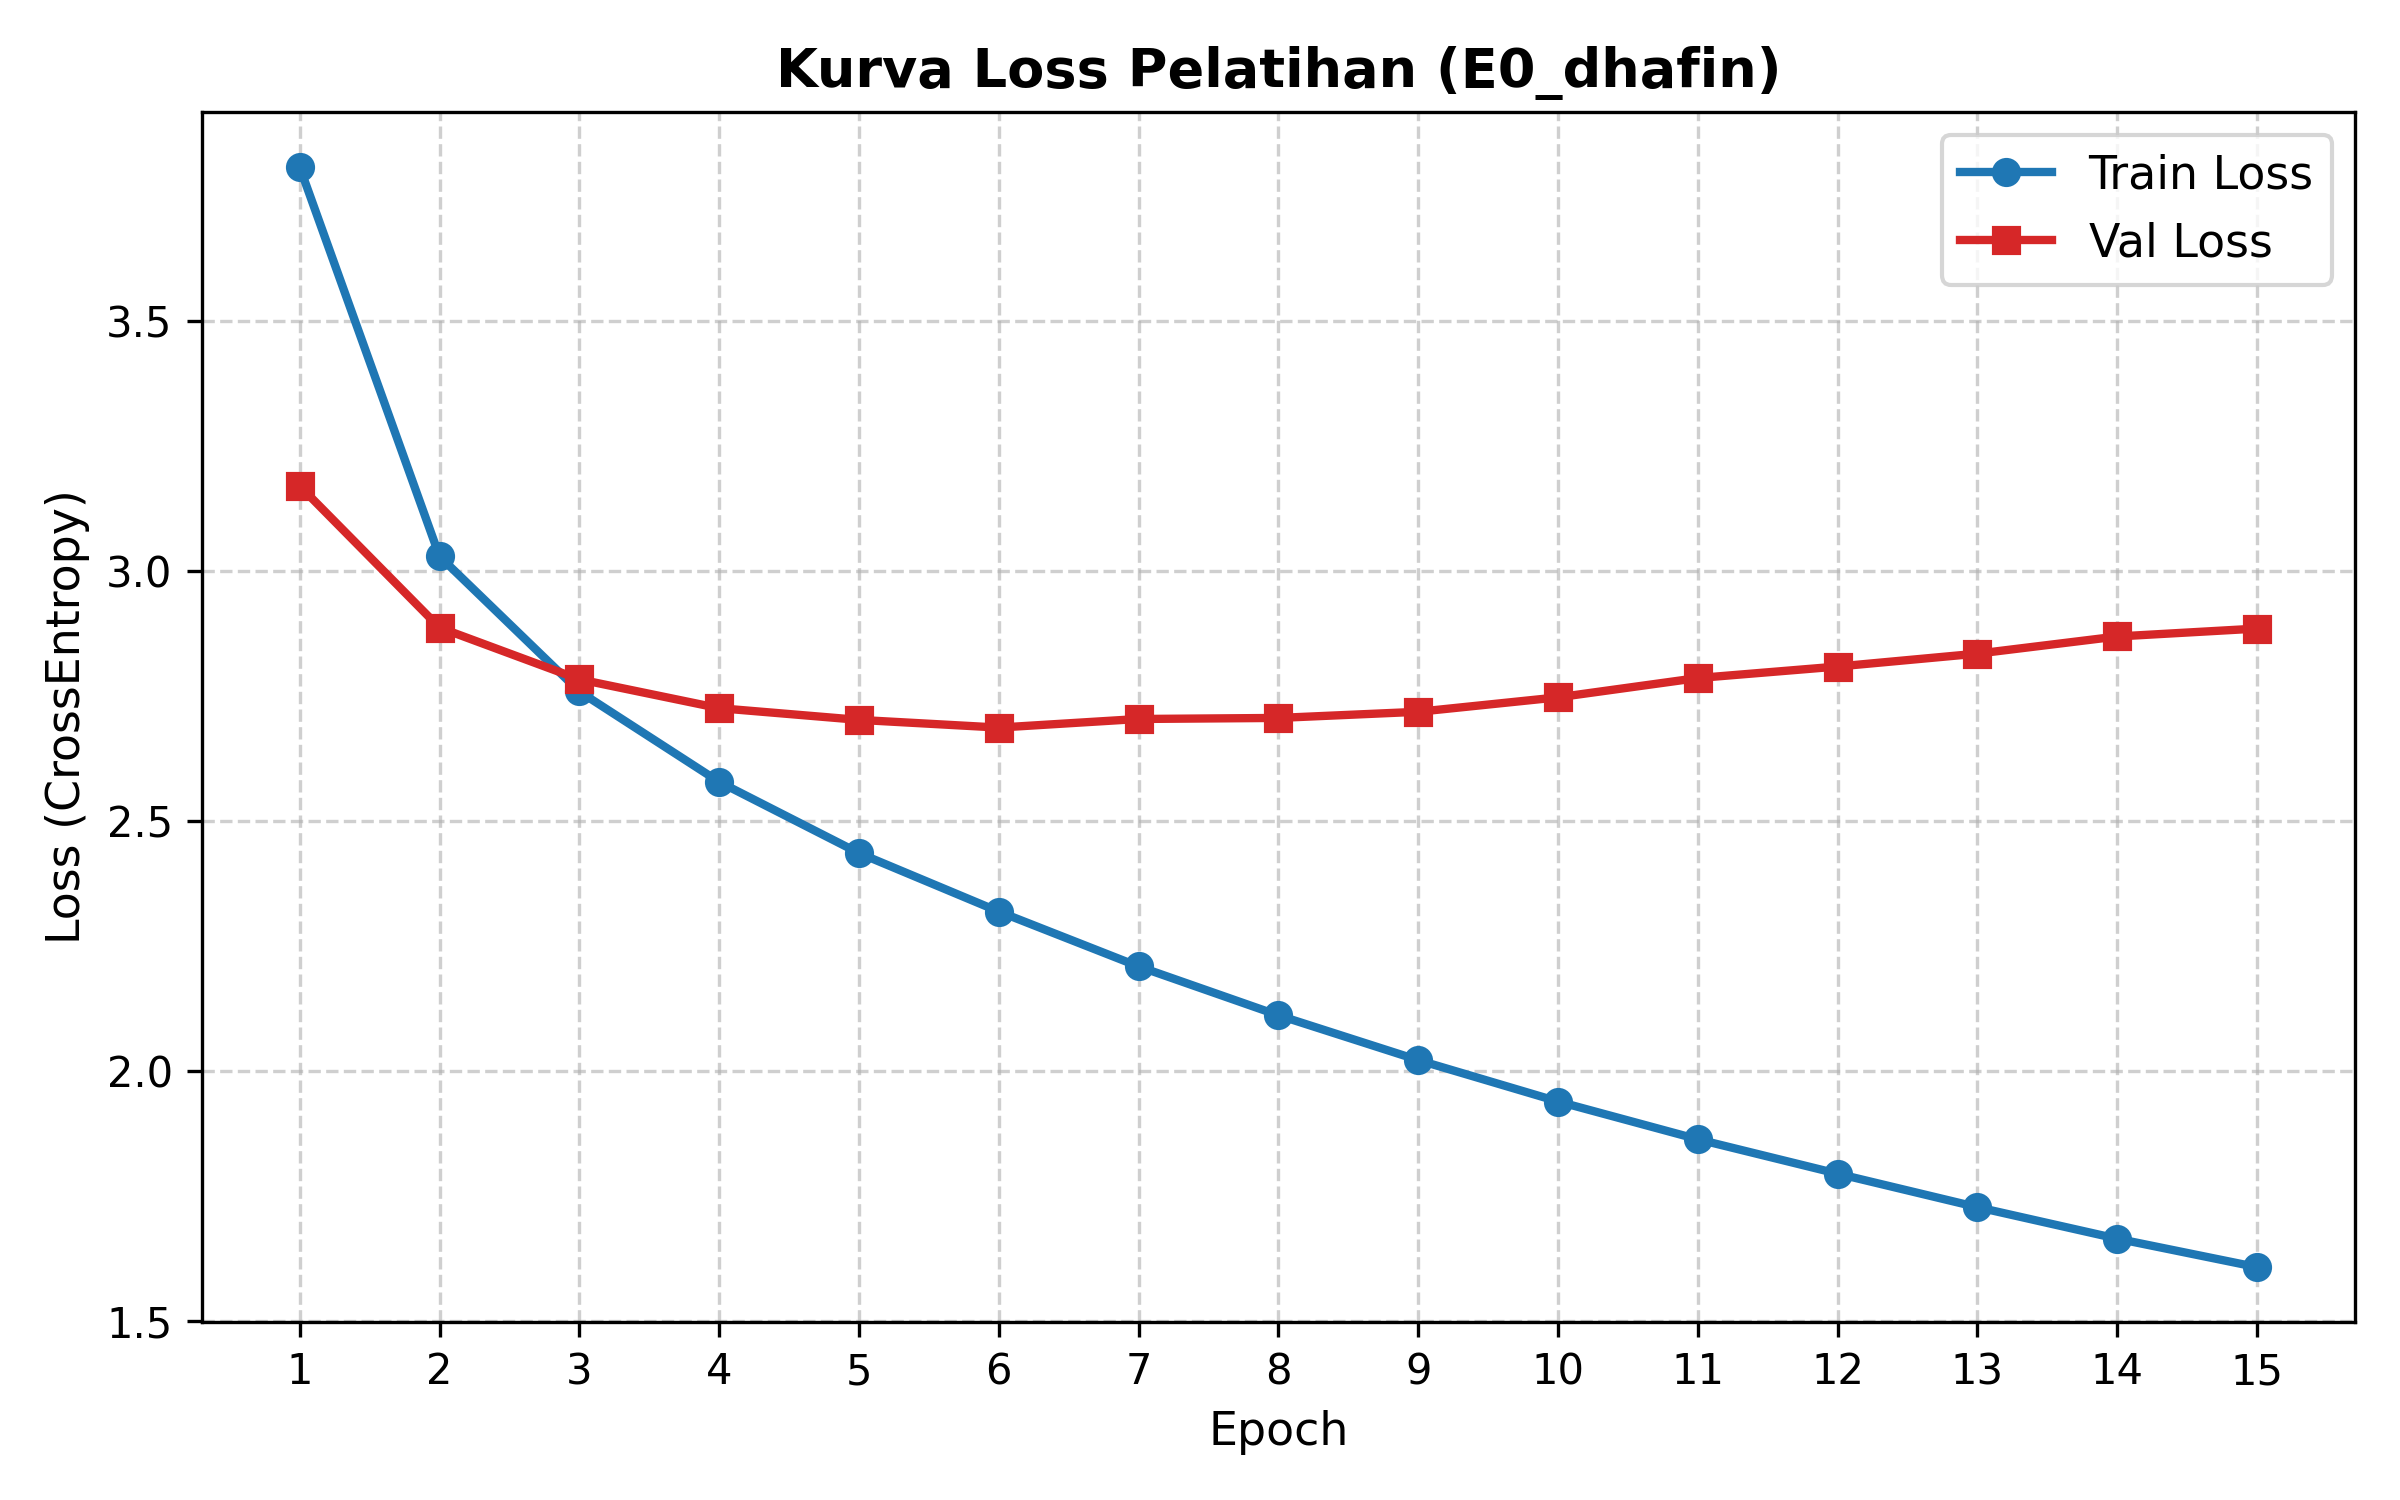


HASIL PREDIKSI MODEL VS REFERENSI (10 SAMPEL)
[01]
  Prediksi : a little boy in a red shirt is playing with a red <unk>
  Referensi: a young boy wearing a blue shirt is playing at a park
------------------------------------------------------------------------------
[02]
  Prediksi : a person is riding a bike on a dirt path
  Referensi: a mountain biker in red is riding on a woodland path
------------------------------------------------------------------------------
[03]
  Prediksi : a man in a red jacket and a red hat is sitting on a rock
  Referensi: the men are climbing
------------------------------------------------------------------------------
[04]
  Prediksi : three dogs are running through a grassy field
  Referensi: two black brown and white dogs running in green grass with ears up on heads
------------------------------------------------------------------------------
[05]
  Prediksi : a dog swims in the water
  Referensi: a person doing the backstroke in an outdoor pool
----

In [31]:
import json
from IPython.display import Image, display

# 1. Muat checkpoint terbaik berdasarkan val_loss terendah
checkpoint_file = f"{ROOT}/checkpoints/best_E0_dhafin.pt"
checkpoint = torch.load(checkpoint_file, map_location=device)
model_e0.load_state_dict(checkpoint['model_state_dict'])

best_epoch = checkpoint.get('epoch', 'N/A')
best_val_loss = checkpoint.get('val_loss', 0.0)
print(f"Berhasil memuat checkpoint terbaik dari Epoch {best_epoch} (Val Loss: {best_val_loss:.4f})")

# 2. Muat set evaluasi validasi (1000 gambar, 5 caption referensi per gambar)
# CATATAN: Data test TIDAK dimuat pada tahap ini (khusus model final)
_, feature_tensor_val, references_val = get_eval_set('val', features_dir=FEAT)
eval_items_val = list(zip(feature_tensor_val, references_val))

# 3. Evaluasi metrik korpus BLEU-1 sampai BLEU-4
print("Menghitung skor korpus BLEU pada subset validasi...")
bleu_scores = evaluate_bleu(
    model=model_e0,
    eval_items=eval_items_val,
    idx2word=idx2word,
    device=device,
    batch_size=64,
    max_len=30
)

# 4. Simpan konfigurasi eksperimen dan hasil evaluasi ke berkas JSON
eval_summary = {
    "exp_name": "E0_dhafin",
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "train_loss_at_best": checkpoint.get('train_loss', None),
    "config": {
        "epochs": 15,
        "lr": 1e-3,
        "batch_size": 64,
        "feature_dim": 2048,
        "embed_dim": 256,
        "hidden_size": 512,
        "dropout_p": 0.5,
        "vocab_size": vocab_size,
        "split_eval": "val"
    },
    "bleu_scores": bleu_scores
}

json_save_path = f"{ROOT}/results/E0_dhafin_bleu.json"
with open(json_save_path, mode="w", encoding="utf-8") as f:
    json.dump(eval_summary, f, indent=4)
print(f"Skor BLEU dan konfigurasi disimpan ke: {json_save_path}")

print("\nRekap Skor BLEU Validasi (E0 Baseline):")
for metric, score in bleu_scores.items():
    print(f"  {metric:<8}: {score:.4f} ({score * 100:.2f}%)")

# 5. Buat dan tampilkan grafik kurva loss secara inline
csv_history_path = f"{ROOT}/results/E0_dhafin.csv"
loss_plot_path = f"{ROOT}/results/E0_dhafin_loss.png"

plot_history(csv_path=csv_history_path, save_path=loss_plot_path)
print(f"\nGrafik kurva loss tersimpan di: {loss_plot_path}")
display(Image(filename=loss_plot_path))

# 6. Cetak 10 sampel kualitatif prediksi model vs kalimat referensi manusia
show_samples(
    model=model_e0,
    eval_items=eval_items_val,
    idx2word=idx2word,
    device=device,
    n=10
)

In [21]:
import os
from pathlib import Path
from google.colab import drive
import torch

print("1. Melakukan force remount Google Drive...")
drive.flush_and_unmount()
drive.mount('/content/drive', force_remount=True)

# 2. Definisikan jalur direktori proyek
ROOT = Path('/content/drive/MyDrive/Kelompok9')
CHECKPOINTS_DIR = ROOT / 'checkpoints'
RESULTS_DIR = ROOT / 'results'

# Buat ulang folder jika belum tersedia
CHECKPOINTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"\n2. Memeriksa keberadaan folder:")
print(f"   - checkpoints/ : {'ADA' if CHECKPOINTS_DIR.is_dir() else 'TIDAK DITEMUKAN'}")
print(f"   - results/     : {'ADA' if RESULTS_DIR.is_dir() else 'TIDAK DITEMUKAN'}")

# 3. Uji integritas tulis dan baca file biner di checkpoints/
test_file = CHECKPOINTS_DIR / 'io_test.pt'
dummy_payload = {'status': 'ok', 'timestamp': '2026-10-31'}

print("\n3. Menguji operasi I/O...")
try:
    torch.save(dummy_payload, test_file)
    loaded_payload = torch.load(test_file, map_location='cpu')
    assert loaded_payload['status'] == 'ok'
    test_file.unlink()  # Hapus file uji setelah verifikasi
    print("   ✅ Uji Tulis-Baca I/O BERHASIL: Folder checkpoints siap digunakan.")
except Exception as e:
    print(f"   ❌ Uji I/O GAGAL: {e}")

1. Melakukan force remount Google Drive...
Mounted at /content/drive

2. Memeriksa keberadaan folder:
   - checkpoints/ : ADA
   - results/     : ADA

3. Menguji operasi I/O...
   ✅ Uji Tulis-Baca I/O BERHASIL: Folder checkpoints siap digunakan.


In [27]:
%%writefile /content/drive/MyDrive/Kelompok9/src/train_utils.py
"""
src/train_utils.py
Modul pelatihan dan evaluasi PyTorch untuk Image Captioning (Kelompok 9).

Pembaruan V2:
- Caching bobot terbaik di RAM CPU selama training (bebas disk I/O & race condition).
- Penulisan checkpoint fisik SEKALI di akhir pelatihan:
  1. Tulis ke /content/checkpoints/ (SSD lokal Colab).
  2. Hapus file lama di Drive jika ada.
  3. Salin ke Google Drive via shutil.copy2.
  4. Verifikasi integritas file via torch.load dari Drive.
- optimizer_state_dict dihilangkan untuk mereduksi ukuran file (~65% lebih hemat).
- Format CSV tetap: epoch, train_loss, val_loss, lr, seconds.
"""

import os
import csv
import time
import shutil
import random
from pathlib import Path
from typing import Dict, List, Union

import numpy as np
import torch
import torch.nn as nn
from torch.optim import Optimizer
from torch.utils.data import DataLoader


def set_seed(seed: int = 42) -> None:
    """
    Mengunci seluruh generator bilangan acak untuk menjamin reproduksibilitas.

    Args:
        seed (int): Nilai seed acak (default: 42 sesuai kontrak).
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    optimizer: Optimizer,
    device: torch.device,
    clip: float = 5.0,
) -> float:
    """
    Melatih model selama satu epoch penuh menggunakan skema Teacher Forcing.

    Args:
        model (nn.Module): Model decoder image captioning.
        loader (DataLoader): DataLoader batch (features [B, 2048], captions [B, 30]).
        criterion (nn.Module): Fungsi kerugian (CrossEntropyLoss dengan ignore_index=0).
        optimizer (Optimizer): Optimizer pembaruan bobot (Adam).
        device (torch.device): Perangkat komputasi (cuda atau cpu).
        clip (float, optional): Batas ambang maksimum pemotongan gradien. Default: 5.0.

    Returns:
        float: Rata-rata training loss pada epoch tersebut.
    """
    model.train()
    total_loss = 0.0
    num_batches = len(loader)

    for features, captions in loader:
        features = features.to(device, non_blocking=True)
        captions = captions.to(device, non_blocking=True)

        # Penjajaran Teacher Forcing sesuai kontrak:
        # Input decoder: membuang token terakhir [B, T-1] -> [B, 29]
        # Target label: membuang token awal <start> [B, T-1] -> [B, 29]
        captions_in = captions[:, :-1]
        targets = captions[:, 1:]

        optimizer.zero_grad()

        # Forward pass menghasilkan raw logits [B, 29, V]
        logits = model(features, captions_in)

        # Perataan dimensi sesuai kontrak:
        # logits [B, 29, V] -> [B * 29, V]
        # targets [B, 29] -> [B * 29]
        vocab_size = logits.size(-1)
        loss = criterion(logits.reshape(-1, vocab_size), targets.reshape(-1))

        # Backward pass & Gradient clipping untuk kestabilan LSTM
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=clip)
        optimizer.step()

        total_loss += loss.item()

    return total_loss / num_batches if num_batches > 0 else 0.0


def evaluate(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
) -> float:
    """
    Mengevaluasi loss model pada dataset validasi tanpa komputasi gradien.

    Args:
        model (nn.Module): Model decoder image captioning.
        loader (DataLoader): DataLoader validasi (features [B, 2048], captions [B, 30]).
        criterion (nn.Module): Fungsi kerugian (CrossEntropyLoss dengan ignore_index=0).
        device (torch.device): Perangkat komputasi.

    Returns:
        float: Rata-rata validation loss.
    """
    model.eval()
    total_loss = 0.0
    num_batches = len(loader)

    with torch.no_grad():
        for features, captions in loader:
            features = features.to(device, non_blocking=True)
            captions = captions.to(device, non_blocking=True)

            captions_in = captions[:, :-1]
            targets = captions[:, 1:]

            logits = model(features, captions_in)
            vocab_size = logits.size(-1)
            loss = criterion(logits.reshape(-1, vocab_size), targets.reshape(-1))

            total_loss += loss.item()

    return total_loss / num_batches if num_batches > 0 else 0.0


def fit(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    epochs: int,
    lr: float,
    device: torch.device,
    exp_name: str,
    root: Union[str, Path] = ".",
) -> Dict[str, List[float]]:
    """
    Loop pelatihan multi-epoch dengan optimizer Adam.
    Menyimpan state_dict terbaik di memori CPU selama iterasi, lalu menulis
    checkpoint sekali di akhir pelatihan ke SSD lokal sebelum disalin ke Drive.

    Args:
        model (nn.Module): Model decoder image captioning.
        train_loader (DataLoader): DataLoader subset training.
        val_loader (DataLoader): DataLoader subset validasi.
        epochs (int): Jumlah iterasi pelatihan.
        lr (float): Learning rate untuk optimizer Adam.
        device (torch.device): Perangkat komputasi (cuda / cpu).
        exp_name (str): Nama eksperimen (misalnya: 'E0_dhafin').
        root (Union[str, Path], optional): Jalur folder root proyek Google Drive. Default: '.'.

    Returns:
        Dict[str, List[float]]: Rekapitulasi riwayat metrik selama pelatihan.
    """
    root_path = Path(root)
    checkpoints_dir = root_path / "checkpoints"
    results_dir = root_path / "results"

    checkpoints_dir.mkdir(parents=True, exist_ok=True)
    results_dir.mkdir(parents=True, exist_ok=True)

    # Direktori lokal di lingkungan Colab (cepat dan aman dari gangguan FUSE)
    local_checkpoints_dir = Path("/content/checkpoints")
    local_checkpoints_dir.mkdir(parents=True, exist_ok=True)

    local_checkpoint_file = local_checkpoints_dir / f"best_{exp_name}.pt"
    drive_checkpoint_file = checkpoints_dir / f"best_{exp_name}.pt"
    csv_file = results_dir / f"{exp_name}.csv"

    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable_params, lr=lr)
    criterion = nn.CrossEntropyLoss(ignore_index=0)

    # Variabel in-memory untuk menyimpan bobot terbaik tanpa disk I/O
    best_val_loss = float("inf")
    best_epoch = -1
    best_train_loss = 0.0
    best_lr = lr
    best_model_state: Dict[str, torch.Tensor] = None

    history: Dict[str, List[float]] = {
        "epoch": [],
        "train_loss": [],
        "val_loss": [],
        "lr": [],
        "seconds": [],
    }

    # Inisialisasi berkas CSV riwayat metrik
    with open(csv_file, mode="w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["epoch", "train_loss", "val_loss", "lr", "seconds"])

    print(f"Mulai eksperimen: {exp_name} | Epochs: {epochs} | LR: {lr} | Target Device: {device}")
    print("-" * 80)

    for epoch in range(1, epochs + 1):
        start_time = time.time()

        train_loss = train_one_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=device,
            clip=5.0,
        )

        val_loss = evaluate(
            model=model,
            loader=val_loader,
            criterion=criterion,
            device=device,
        )

        elapsed_seconds = round(time.time() - start_time, 2)
        current_lr = optimizer.param_groups[0]["lr"]

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["lr"].append(current_lr)
        history["seconds"].append(elapsed_seconds)

        # Tulis entri epoch ke berkas CSV (CSV berukuran kecil, ~100 byte, aman untuk FUSE)
        with open(csv_file, mode="a", newline="", encoding="utf-8") as f:
            writer = csv.writer(f)
            writer.writerow([epoch, f"{train_loss:.4f}", f"{val_loss:.4f}", f"{current_lr:.6f}", elapsed_seconds])

        # Simpan ke RAM CPU jika val_loss membaik (bebas penulisan disk lambat)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_train_loss = train_loss
            best_lr = current_lr
            # Salin state_dict ke CPU RAM secara terisolasi
            best_model_state = {
                k: v.detach().cpu().clone() for k, v in model.state_dict().items()
            }
            status_simpan = " [BEST MEMORY]"
        else:
            status_simpan = ""

        print(
            f"Epoch [{epoch:02d}/{epochs:02d}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"LR: {current_lr:.6f} | "
            f"Waktu: {elapsed_seconds:>5.2f}s{status_simpan}"
        )

    print("-" * 80)

    # PROSES PENULISAN CHECKPOINT TUNGGAL DI AKHIR PELATIHAN
    if best_model_state is not None:
        checkpoint_payload = {
            "model_state_dict": best_model_state,
            "epoch": best_epoch,
            "val_loss": best_val_loss,
            "train_loss": best_train_loss,
            "lr": best_lr,
            "exp_name": exp_name,
        }

        # 1. Tulis dulu ke SSD lokal Colab
        torch.save(checkpoint_payload, local_checkpoint_file)
        local_size_mb = local_checkpoint_file.stat().st_size / (1024 * 1024)
        print(f"1. Checkpoint lokal berhasil ditulis di {local_checkpoint_file} ({local_size_mb:.2f} MB)")

        # 2. Hapus file lama di Drive jika ada (membersihkan objek lama dari sistem FUSE)
        if drive_checkpoint_file.exists():
            try:
                drive_checkpoint_file.unlink()
                print(f"2. File lama di Drive berhasil dibersihkan.")
            except Exception as e:
                print(f"2. Catatan pembersihan Drive: {e}")
        else:
            print("2. Tidak ada file lama yang perlu dibersihkan di Drive.")

        # 3. Salin file dari lokal ke Google Drive
        shutil.copy2(local_checkpoint_file, drive_checkpoint_file)
        print(f"3. Salinan checkpoint berhasil ditransfer ke Google Drive: {drive_checkpoint_file}")

        # 4. Verifikasi pembacaan langsung dari Google Drive
        try:
            verified_payload = torch.load(drive_checkpoint_file, map_location="cpu")
            assert "model_state_dict" in verified_payload
            print(f"4. ✅ VERIFIKASI BERHASIL: Checkpoint Drive terbaca utuh (Epoch {best_epoch}, Val Loss: {best_val_loss:.4f})")
        except Exception as e:
            print(f"4. ❌ VERIFIKASI GAGAL: Terjadi galat saat membaca file di Drive: {e}")
            print(f"   Cadangan lokal tetap tersedia di: {local_checkpoint_file}")
    else:
        print("Peringatan: Tidak ada checkpoint yang disimpan.")

    print(f"Log pelatihan tersimpan di : {csv_file}")
    return history

Overwriting /content/drive/MyDrive/Kelompok9/src/train_utils.py


In [28]:
import os
from pathlib import Path

chk_dir = Path("/content/drive/MyDrive/Kelompok9/checkpoints")

# Hapus seluruh instansi best_E0_dhafin.pt yang bertumpuk
for f in chk_dir.glob("*best_E0_dhafin*"):
    try:
        f.unlink()
        print(f"Dihapus: {f.name}")
    except Exception as e:
        print(f"Gagal menghapus {f.name}: {e}")

print("Pembersihan selesai. Siap menjalankan Sel A, Sel B, dan Sel C.")

Pembersihan selesai. Siap menjalankan Sel A, Sel B, dan Sel C.
